In [1]:
# libraries
import os
import json
import time
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import nbformat
from IPython.display import display

In [2]:
# globals; run through run_pipeline.ipynb
ROOT = Path(os.environ['NCA_PROJECT_ROOT'])
TASK = ROOT / 'h_compare'
INPUT, OUTPUT = TASK / 'input', TASK / 'output'
CFG = json.loads((INPUT / 'config.json').read_text())
DEVICE = torch.device(CFG['device'])
torch.set_num_threads(CFG['cpu_threads'])
torch.use_deterministic_algorithms(True)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

In [3]:
# functions passed through c_models/output; definitions only, no training side effects
runtime_nb = nbformat.read(INPUT / 'runtime.ipynb', as_version=4)
for runtime_cell in runtime_nb.cells:
    exec(compile(runtime_cell.source, 'runtime.ipynb', 'exec'), globals())
PACK = torch.load(INPUT / 'dataset.pt', weights_only=True, map_location='cpu')
SPECS = CFG['models']

In [4]:
# table imports
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
from IPython.display import Image as NotebookImage
phase1 = pd.read_csv(INPUT / 'phase1_metrics.csv')
phase2 = pd.read_csv(INPUT / 'phase2_metrics.csv')
samples = pd.read_csv(INPUT / 'phase2_calibration_samples.csv')
transitions = pd.read_csv(INPUT / 'phase2_transition_summary.csv')
phase1_runs = pd.read_csv(INPUT / 'phase1_manifest.csv')
phase2_runs = pd.read_csv(INPUT / 'phase2_manifest.csv')
architectures = pd.read_csv(INPUT / 'architectures.csv')
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
MODEL_ORDER = [spec['name'] for spec in SPECS]
COLORS = dict(zip(MODEL_ORDER, sns.color_palette('colorblind', 6)))
MARKERS = dict(zip(MODEL_ORDER, ['o', 's', '^', 'D', 'v', 'P']))
DASHES = dict(zip(MODEL_ORDER, ['', (3, 1), (5, 2), (1, 1), (4, 1, 1, 1), (2, 1, 2, 3)]))
STATUS = 'SMOKE: execution check only' if CFG['profile'] == 'smoke' else CFG['profile'].upper()

In [5]:
# reconstruction summary; first average condition/channel repeats within each trained replicate
summary_frames = []
for phase, source in [(1, phase1), (2, phase2)]:
    clean = source.query("intervention == 'none' and flip_rate == 0")
    metrics = ['mse', 'foreground_rmse', 'alpha_iou'] + (['successful_generation'] if phase == 2 else [])
    within = clean.groupby(['model', 'regime', 'replicate', 'split'])[metrics].mean().reset_index()
    within['phase'] = phase
    summary_frames.append(within)
replicate_scores = pd.concat(summary_frames, ignore_index=True)
replicate_scores.to_csv(OUTPUT / 'replicate_scores.csv', index=False)
comparison = paired_bootstrap(replicate_scores, ['phase', 'model', 'regime', 'split'],
                             ['mse', 'foreground_rmse', 'alpha_iou'], CFG)
comparison['profile'] = CFG['profile']
comparison.to_csv(OUTPUT / 'comparison.csv', index=False)
paired_bootstrap(replicate_scores.query('phase == 2'), ['phase', 'model', 'regime', 'split'],
                 ['successful_generation'], CFG).to_csv(OUTPUT / 'generation_success.csv', index=False)
# confirm the budget controls were actually satisfied during training
budget_checks = []
for phase, runs in [(1, phase1_runs), (2, phase2_runs)]:
    for (regime, replicate), group in runs.groupby(['regime', 'replicate']):
        column = 'training_bits' if regime == 'bits' else 'training_cell_updates'
        assert group[column].nunique() == 1, f'{phase}: unmatched {regime} budget'
        budget_checks.append({'phase': phase, 'regime': regime, 'replicate': replicate, 'matched_quantity': column,
                              'value_per_run': group[column].iloc[0], 'passed': True})
pd.DataFrame(budget_checks).to_csv(OUTPUT / 'budget_checks.csv', index=False)
display(comparison)

,phase,model,regime,split,metric,mean,n_replicates,ci_low,ci_high,profile
0,1,1A_bern,bits,test_angle,mse,0.032357,1,NaN,NaN,smoke
1,1,1A_bern,bits,test_angle,foreground_rmse,0.567691,1,NaN,NaN,smoke
2,1,1A_bern,bits,test_angle,alpha_iou,0.000000,1,NaN,NaN,smoke
3,1,1A_bern,bits,test_color,mse,0.034568,1,NaN,NaN,smoke
4,1,1A_bern,bits,test_color,foreground_rmse,0.596728,1,NaN,NaN,smoke
...,...,...,...,...,...,...,...,...,...,...
355,2,1B_rbern,updates,test_joint,foreground_rmse,0.607400,1,NaN,NaN,smoke
356,2,1B_rbern,updates,test_joint,alpha_iou,0.000000,1,NaN,NaN,smoke
357,2,1B_rbern,updates,test_translation,mse,0.041764,1,NaN,NaN,smoke
358,2,1B_rbern,updates,test_translation,foreground_rmse,0.644914,1,NaN,NaN,smoke


In [6]:
# paired contrasts use matched replicate streams; CIs omitted for the one-replicate pilot
contrasts = [('1A_bern', '1A_det'), ('1B_det', '1A_det'), ('1B_qbern', '1B_det'),
             ('1B_rbern', '1B_det'), ('1B_qrbern', '1B_det')]
contrast_rows = []
for (phase, regime, split), group in replicate_scores.groupby(['phase', 'regime', 'split']):
    pivot = group.pivot(index='replicate', columns='model', values='foreground_rmse')
    for treatment, baseline in contrasts:
        delta = pivot[treatment] - pivot[baseline]
        for replicate, value in delta.items():
            contrast_rows.append({'phase': phase, 'regime': regime, 'split': split, 'replicate': replicate,
                                  'contrast': f'{treatment} minus {baseline}', 'delta_foreground_rmse': value})
contrast_df = pd.DataFrame(contrast_rows)
paired_bootstrap(contrast_df, ['phase', 'regime', 'split', 'contrast'], ['delta_foreground_rmse'], CFG).to_csv(
    OUTPUT / 'paired_contrasts.csv', index=False)

In [7]:
# mixture calibration; invalid forms remain unresolved, with lower/upper smile-frequency bounds
samples['confirmed_smiley'] = samples['valid'] & samples['predicted_class'].eq(1)
samples['unresolved'] = ~samples['valid']
latent_units = samples.groupby(['model', 'regime', 'replicate', 'probability', 'latent_id']).agg(
    confirmed_smiley=('confirmed_smiley', 'mean'), unresolved=('unresolved', 'mean'),
    success=('successful_generation', 'mean'), intended=('intended_class', 'first')).reset_index()
calibration_rows = []
rng = numpy_stream(CFG, 6200)
for key, group in latent_units.groupby(['model', 'regime', 'replicate', 'probability']):
    model_name, regime, replicate, probability = key
    frequency = group['confirmed_smiley'].mean()
    unknown = group['unresolved'].mean()
    draws = rng.choice(group['confirmed_smiley'].to_numpy(), (1000, len(group)), replace=True).mean(1)
    calibration_rows.append({'model': model_name, 'regime': regime, 'replicate': replicate, 'probability': probability,
                             'confirmed_smiley_fraction': frequency, 'unresolved_fraction': unknown,
                             'smiley_frequency_lower': frequency, 'smiley_frequency_upper': frequency + unknown,
                             'target_smiley_fraction_in_draws': group['intended'].mean(),
                             'latent_choice_accuracy': group['success'].mean(), 'n_latents': len(group),
                             'latent_bootstrap_low': np.quantile(draws, 0.025), 'latent_bootstrap_high': np.quantile(draws, 0.975),
                             'absolute_error_to_p': abs(frequency - probability),
                             'absolute_error_to_latent_selector': abs(frequency - group['intended'].mean())})
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(OUTPUT / 'probability_calibration.csv', index=False)
display(calibration)

,model,regime,replicate,probability,confirmed_smiley_fraction,unresolved_fraction,smiley_frequency_lower,smiley_frequency_upper,target_smiley_fraction_in_draws,latent_choice_accuracy,n_latents,latent_bootstrap_low,latent_bootstrap_high,absolute_error_to_p,absolute_error_to_latent_selector
0,1A_bern,bits,0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4,0.0,0.0,0.0,0.0
1,1A_bern,bits,0,0.5,0.0,1.0,0.0,1.0,0.5,0.0,4,0.0,0.0,0.5,0.5
2,1A_bern,bits,0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,4,0.0,0.0,1.0,1.0
3,1A_bern,updates,0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4,0.0,0.0,0.0,0.0
4,1A_bern,updates,0,0.5,0.0,1.0,0.0,1.0,0.5,0.0,4,0.0,0.0,0.5,0.5
5,1A_bern,updates,0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,4,0.0,0.0,1.0,1.0
6,1A_det,bits,0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4,0.0,0.0,0.0,0.0
7,1A_det,bits,0,0.5,0.0,1.0,0.0,1.0,0.5,0.0,4,0.0,0.0,0.5,0.5
8,1A_det,bits,0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,4,0.0,0.0,1.0,1.0
9,1A_det,updates,0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4,0.0,0.0,0.0,0.0


In [8]:
# response summary: distinguish valid starting forms, successful responses and censored latency
response_rows = []
for key, group in transitions.groupby(['model', 'regime', 'replicate']):
    model_name, regime, replicate = key
    eligible = group.loc[group['eligible_start']]
    successes = eligible.loc[eligible['responded_by_horizon']]
    response_rows.append({'model': model_name, 'regime': regime, 'replicate': replicate,
                          'n_switches': len(group), 'n_valid_starts': len(eligible),
                          'valid_start_fraction': group['eligible_start'].mean(),
                          'adaptation_success_all_starts': group['adapted_from_valid_start'].mean(),
                          'response_success_given_valid_start': eligible['responded_by_horizon'].mean(),
                          'median_latency_successes_only': successes['latency_steps'].median(),
                          'latency_success_count': len(successes)})
response_df = pd.DataFrame(response_rows)
response_df.to_csv(OUTPUT / 'online_response.csv', index=False)
display(response_df)

,model,regime,replicate,n_switches,n_valid_starts,valid_start_fraction,adaptation_success_all_starts,response_success_given_valid_start,median_latency_successes_only,latency_success_count
0,1A_bern,bits,0,4,0,0.0,0.0,NaN,NaN,0
1,1A_bern,updates,0,4,0,0.0,0.0,NaN,NaN,0
2,1A_det,bits,0,4,0,0.0,0.0,NaN,NaN,0
3,1A_det,updates,0,4,0,0.0,0.0,NaN,NaN,0
4,1B_det,bits,0,4,0,0.0,0.0,NaN,NaN,0
5,1B_det,updates,0,4,0,0.0,0.0,NaN,NaN,0
6,1B_qbern,bits,0,4,0,0.0,0.0,NaN,NaN,0
7,1B_qbern,updates,0,4,0,0.0,0.0,NaN,NaN,0
8,1B_qrbern,bits,0,4,0,0.0,0.0,NaN,NaN,0
9,1B_qrbern,updates,0,4,0,0.0,0.0,NaN,NaN,0


In [9]:
# cat retention after multi-template training; paired by run and held-out condition
before = phase1.query("intervention == 'none' and flip_rate == 0 and split == 'test_composition'").groupby(
    ['model', 'regime', 'replicate', 'condition'])['foreground_rmse'].mean().rename('before')
after = phase2.query("intervention == 'cat_retention'").groupby(
    ['model', 'regime', 'replicate', 'condition'])['foreground_rmse'].mean().rename('after')
retention = pd.concat([before, after], axis=1).reset_index()
retention['change_in_cat_rmse'] = retention['after'] - retention['before']
retention.to_csv(OUTPUT / 'cat_retention.csv', index=False)

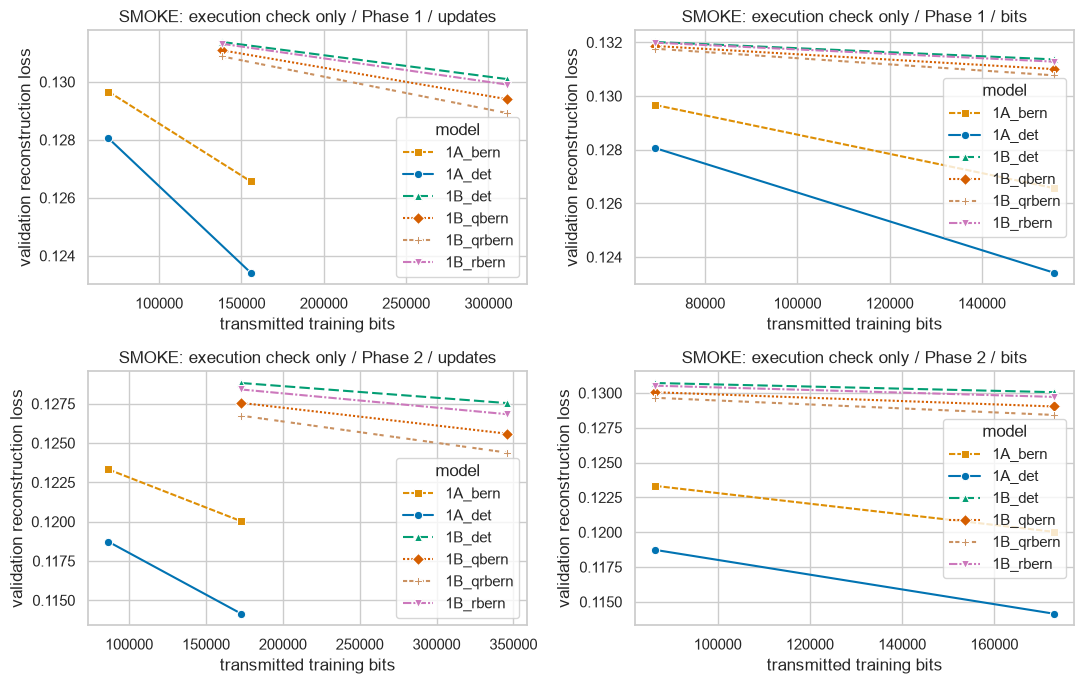

In [10]:
# training curves use actual consumed bits; both training phases have separate optimizers
history_frames = []
for phase, runs in [(1, phase1_runs), (2, phase2_runs)]:
    for run in runs.to_dict('records'):
        history = pd.read_csv(INPUT / f'phase{phase}_runs' / Path(run['checkpoint']).parent / 'history.csv')
        for column in ['model', 'regime', 'replicate']:
            history[column] = run[column]
        history['phase'] = phase
        history_frames.append(history)
histories = pd.concat(history_frames, ignore_index=True)
histories.to_csv(OUTPUT / 'training_history.csv', index=False)
fig, axes = plt.subplots(2, len(CFG['budget_regimes']), figsize=(11, 7), squeeze=False)
for row, phase in enumerate([1, 2]):
    for column, regime in enumerate(CFG['budget_regimes']):
        panel = histories.query('phase == @phase and regime == @regime').groupby(['model', 'step']).agg(
            val_loss=('val_loss', 'mean'), total_bits=('total_bits', 'mean')).reset_index()
        sns.lineplot(data=panel, x='total_bits', y='val_loss', hue='model', style='model',
                     palette=COLORS, markers=MARKERS, dashes=DASHES, ax=axes[row, column])
        axes[row, column].set_title(f'{STATUS} / Phase {phase} / {regime}')
        axes[row, column].set_xlabel('transmitted training bits')
        axes[row, column].set_ylabel('validation reconstruction loss')
fig.tight_layout()
fig.savefig(OUTPUT / 'training_curves.png', dpi=170)
plt.show()

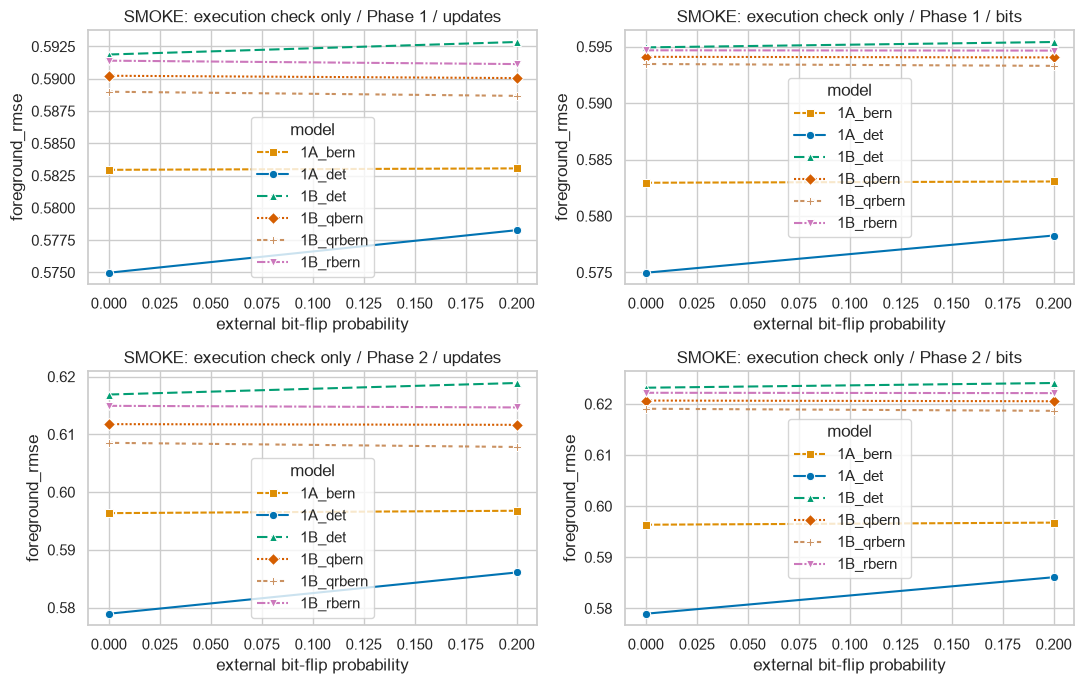

In [11]:
# held-out performance vs bit-flip stress
stress_frames = []
for phase, source in [(1, phase1), (2, phase2)]:
    stress = source.query("intervention == 'none'").groupby(['model', 'regime', 'replicate', 'flip_rate'])[
        ['foreground_rmse']].mean().reset_index()
    stress['phase'] = phase
    stress_frames.append(stress)
stress_df = pd.concat(stress_frames, ignore_index=True)
stress_df.to_csv(OUTPUT / 'noise_stress.csv', index=False)
fig, axes = plt.subplots(2, len(CFG['budget_regimes']), figsize=(11, 7), squeeze=False)
for row, phase in enumerate([1, 2]):
    for column, regime in enumerate(CFG['budget_regimes']):
        panel = stress_df.query('phase == @phase and regime == @regime').groupby(['model', 'flip_rate'])['foreground_rmse'].mean().reset_index()
        sns.lineplot(data=panel, x='flip_rate', y='foreground_rmse', hue='model', style='model',
                     palette=COLORS, markers=MARKERS, dashes=DASHES, ax=axes[row, column])
        axes[row, column].set_title(f'{STATUS} / Phase {phase} / {regime}')
        axes[row, column].set_xlabel('external bit-flip probability')
fig.tight_layout()
fig.savefig(OUTPUT / 'noise_robustness.png', dpi=170)
plt.show()

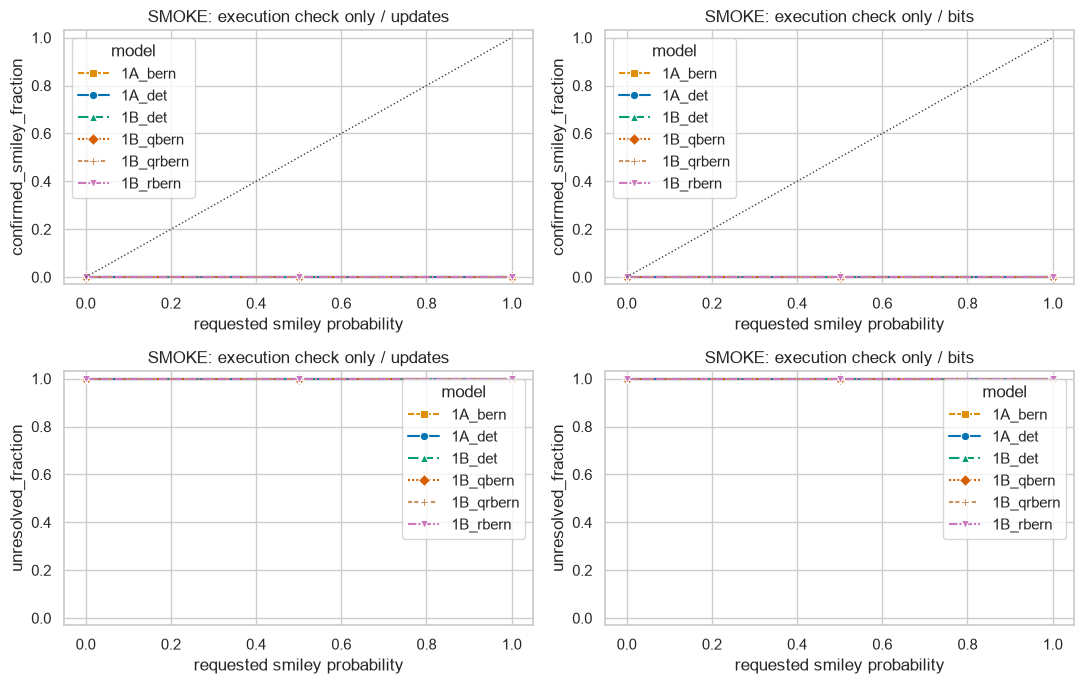

In [12]:
# probability control; lower bounds and unresolved output fractions are shown separately
fig, axes = plt.subplots(2, len(CFG['budget_regimes']), figsize=(11, 7), squeeze=False)
for column, regime in enumerate(CFG['budget_regimes']):
    panel = calibration.query('regime == @regime').groupby(['model', 'probability'])[
        ['confirmed_smiley_fraction', 'unresolved_fraction']].mean().reset_index()
    for row, metric in enumerate(['confirmed_smiley_fraction', 'unresolved_fraction']):
        sns.lineplot(data=panel, x='probability', y=metric, hue='model', style='model',
                     palette=COLORS, markers=MARKERS, dashes=DASHES, ax=axes[row, column])
        axes[row, column].set_ylim(-0.03, 1.03)
        axes[row, column].set_title(f'{STATUS} / {regime}')
        axes[row, column].set_xlabel('requested smiley probability')
    axes[0, column].plot([0, 1], [0, 1], color='0.25', linestyle=':', linewidth=1, label='ideal')
fig.tight_layout()
fig.savefig(OUTPUT / 'probability_control.png', dpi=170)
plt.show()

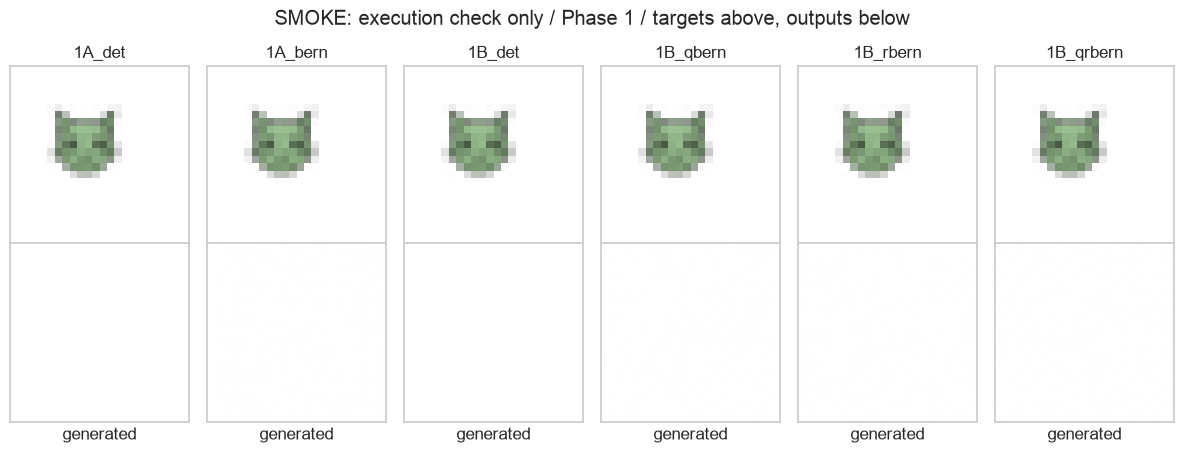

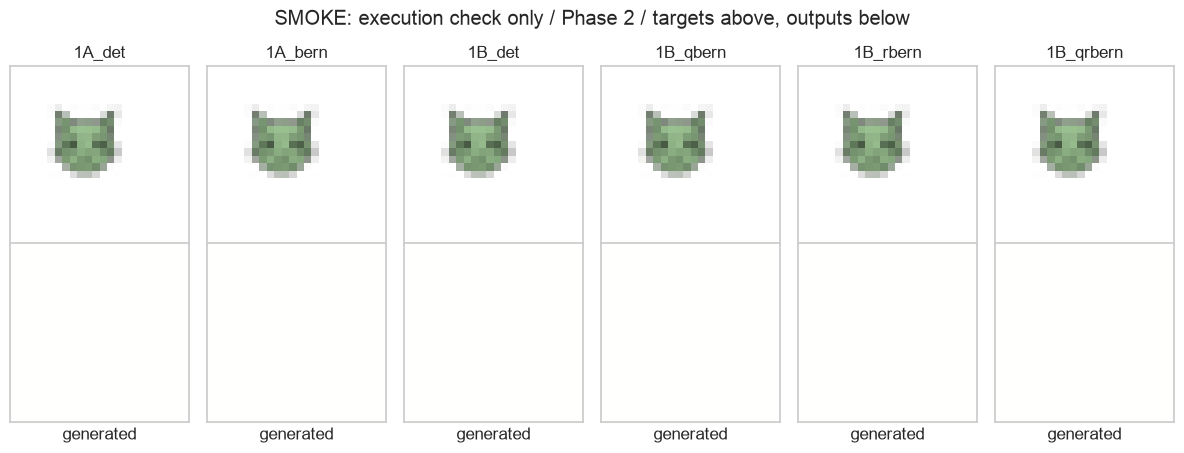

In [13]:
# images use white compositing; predictions are premultiplied colors, not straight-alpha RGBA
def composite(rgba):
    rgba = rgba.detach().cpu().clamp(0, 1).numpy()
    return np.clip(rgba[..., :3] + 1 - rgba[..., 3:4], 0, 1)

for phase in [1, 2]:
    example_data = torch.load(INPUT / f'phase{phase}_examples.pt', weights_only=False)
    selected = [example for example in example_data if example['regime'] == 'updates' and example['replicate'] == 0
                and example['split'] == 'test_composition']
    selected = [next(example for example in selected if example['model'] == name) for name in MODEL_ORDER]
    fig, axes = plt.subplots(2, len(selected), figsize=(12, 4.5))
    for column, example in enumerate(selected):
        axes[0, column].imshow(composite(example['target']))
        axes[1, column].imshow(composite(example['generated']))
        axes[0, column].set_title(example['model'])
        axes[1, column].set_xlabel('generated')
        for row in range(2):
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
    fig.suptitle(f'{STATUS} / Phase {phase} / targets above, outputs below')
    fig.tight_layout()
    fig.savefig(OUTPUT / f'phase{phase}_examples.png', dpi=170)
    plt.show()

In [14]:
# switch animations retain probe times and validity labels; smoke runs visibly carry their status
animation_data = torch.load(INPUT / 'phase2_animations.pt', weights_only=False)
for animation in animation_data:
    frames = []
    for step, rgba in zip(animation['probes'], animation['frames']):
        pixels = Image.fromarray((255 * composite(rgba)).round().astype('uint8')).resize((240, 240), Image.Resampling.NEAREST)
        frame = Image.new('RGB', (420, 290), 'white')
        frame.paste(pixels, (90, 45))
        draw = ImageDraw.Draw(frame)
        draw.text((8, 6), f"{STATUS} | {animation['model']} | t={step}", fill='black')
        draw.text((8, 22), f"cat -> smiley; initial form valid: {animation['eligible_start']}", fill='black')
        frames.append(frame)
    frames[0].save(OUTPUT / f"switch_{animation['model']}.gif", save_all=True, append_images=frames[1:], duration=600, loop=0)

In [15]:
# interpretation and limitations travel with every generated comparison
interpretation = pd.DataFrame([
    ('run status', STATUS),
    ('evidence threshold', 'smoke validates execution only; pilot is exploratory; use independent streams and training diagnostics before conclusions'),
    ('uncertainty', 'replicate bootstrap across trained runs; one-replicate profiles have no between-run CI'),
    ('calibration uncertainty', 'latent-level bootstrap within run; repeated communication draws are clustered by latent'),
    ('fairness', 'both equal updates and equal bits are trained; parameters approximately matched; compute/MACs are reported, not matched'),
    ('pose/color', 'conditional transformation generalization; the architecture does not enforce arbitrary rotation/color equivariance'),
    ('seed access', 'only the seed receives continuous environmental controls; every other site learns them through binary edges'),
    ('bandwidth', 'one bit per directed edge per round, not one total bit received per cell; query+answer costs two rounds'),
    ('deterministic models', 'fixed seed/cues produce one trajectory; differing latent draws or cue schedules permit different outcomes'),
    ('stochastic models', 'Bernoulli probability floor prevents arbitrarily reliable learned messages; exogenous flips are separate stress tests'),
    ('invalid images', 'nearest-template labels are accepted only with quality, margin and alpha-overlap criteria; unresolved outputs remain explicit'),
    ('online response', 'adaptation success requires a valid original form; unsuccessful trials have censored latency'),
    ('latency', 'successful-only median is descriptive and selection-biased; inspect the censored trial-level table'),
    ('generalization unit', 'held-out transformations of two known images; no held-out semantic image classes'),
    ('Phase 2 scope', 'conditional supervised latent generator and changing-cue response; no VAE/GAN objective or autonomous evolution'),
    ('training gradient', 'straight-through sigmoid is biased; strict binary forward communication is preserved'),
    ('substrate', 'all cells are computationally active; no neighbor-alpha life gating that could bypass the bit restriction'),
    ('replication', 'seed 63 and disjoint advanced streams; exact equality across different PyTorch/device versions is not guaranteed')
], columns=['item', 'interpretation'])
interpretation.to_csv(OUTPUT / 'interpretation.csv', index=False)
display(interpretation)
display(architectures)
display(pd.concat([phase1_runs.assign(phase=1), phase2_runs.assign(phase=2)], ignore_index=True))

,item,interpretation
0,run status,SMOKE: execution check only
1,evidence threshold,smoke validates execution only; pilot is explo...
2,uncertainty,replicate bootstrap across trained runs; one-r...
3,calibration uncertainty,latent-level bootstrap within run; repeated co...
4,fairness,both equal updates and equal bits are trained;...
5,pose/color,conditional transformation generalization; the...
6,seed access,only the seed receives continuous environmenta...
7,bandwidth,"one bit per directed edge per round, not one t..."
8,deterministic models,fixed seed/cues produce one trajectory; differ...
9,stochastic models,Bernoulli probability floor prevents arbitrari...


,model,family,regime,width,parameters,parameter_target,macs_per_cell_update,rounds_per_update,steps_at_eval,bits_per_eval_image
0,1A_det,message,updates,22,1219,1200,4246,1,6,25944
1,1A_det,message,bits,22,1219,1200,4246,1,6,25944
2,1A_bern,message,updates,22,1219,1200,4246,1,6,25944
3,1A_bern,message,bits,22,1219,1200,4246,1,6,25944
4,1B_det,query_answer,updates,10,1160,1200,5370,2,6,51888
5,1B_det,query_answer,bits,10,1160,1200,5370,2,3,25944
6,1B_qbern,query_answer,updates,10,1160,1200,5370,2,6,51888
7,1B_qbern,query_answer,bits,10,1160,1200,5370,2,3,25944
8,1B_rbern,query_answer,updates,10,1160,1200,5370,2,6,51888
9,1B_rbern,query_answer,bits,10,1160,1200,5370,2,3,25944


,phase,model,family,regime,replicate,parameters,width,best_step,best_val_loss,signature,optimizer_steps,training_bits,training_cell_updates,seconds,checkpoint
0,1,1A_det,message,updates,0,1219,22,4,0.123413,94736490a0dc383b4cf3e62cb593b64080c35dfe1401a4...,4,155664,20736,0.112913,updates__1A_det__r0/best.pt
1,1,1A_bern,message,updates,0,1219,22,4,0.126565,a4fb07b846b9686a26672aea08af200c8d2497c9448e72...,4,155664,20736,0.087849,updates__1A_bern__r0/best.pt
2,1,1B_det,query_answer,updates,0,1160,10,4,0.130095,be652619f51e3be0dfb2c1ddc4b2d57bc272ec757c8829...,4,311328,20736,0.143442,updates__1B_det__r0/best.pt
3,1,1B_qbern,query_answer,updates,0,1160,10,4,0.129402,25a4df8f6bdd39dd369b3663310bd299b5a5aeea592165...,4,311328,20736,0.142962,updates__1B_qbern__r0/best.pt
4,1,1B_rbern,query_answer,updates,0,1160,10,4,0.129906,79a8f88427b64d0d8f028f1661dbb681e464e57eccf4eb...,4,311328,20736,0.142700,updates__1B_rbern__r0/best.pt
5,1,1B_qrbern,query_answer,updates,0,1160,10,4,0.128922,e36adfa63b22d6c6644e578d342808b1b5d3d4578b28c0...,4,311328,20736,0.143273,updates__1B_qrbern__r0/best.pt
6,1,1A_det,message,bits,0,1219,22,4,0.123413,810a3124d019d845075bf732020ad87d79091d7e497f0b...,4,155664,20736,0.086165,bits__1A_det__r0/best.pt
7,1,1A_bern,message,bits,0,1219,22,4,0.126565,085c41b484503a84738831262f01bace0deda17529eb30...,4,155664,20736,0.085039,bits__1A_bern__r0/best.pt
8,1,1B_det,query_answer,bits,0,1160,10,4,0.131364,942fc06c7cc5b3921f702b115840609f5f32a5244a9888...,4,155664,10368,0.087093,bits__1B_det__r0/best.pt
9,1,1B_qbern,query_answer,bits,0,1160,10,4,0.131001,ae07fd44fd5c3b702111d86b0b833bcc6e2b8520098068...,4,155664,10368,0.094031,bits__1B_qbern__r0/best.pt
